In [31]:
%pip install imbalanced-learn


     -------------------------------------- 236.1/236.1 kB 2.1 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (
    accuracy_score, recall_score, precision_score, f1_score, roc_auc_score
)
RANDOM_STATE = 42




In [4]:
df = pd.read_csv("Dataset\cleaned_cervical_data.csv")

In [5]:
df.shape

(858, 20)

In [6]:
df

,Age,Number of sexual partners,First sexual intercourse,Num of pregnancies,Smokes,Smokes (years),Hormonal Contraceptives,Hormonal Contraceptives (years),IUD,STDs,STDs:condylomatosis,STDs:vaginal condylomatosis,STDs:syphilis,STDs:pelvic inflammatory disease,STDs:genital herpes,STDs:molluscum contagiosum,STDs:HIV,STDs:Hepatitis B,STDs:HPV,Biopsy
0,18,4.0,15.0,1.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
1,15,1.0,14.0,1.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
2,34,1.0,NaN,1.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
3,52,5.0,16.0,4.0,1.0,37.0,1.0,3.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
4,46,3.0,21.0,4.0,0.0,0.0,1.0,15.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
853,34,3.0,18.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
854,32,2.0,19.0,1.0,0.0,0.0,1.0,8.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
855,25,2.0,17.0,0.0,0.0,0.0,1.0,0.08,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
856,33,2.0,24.0,2.0,0.0,0.0,1.0,0.08,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0


In [7]:
df['Biopsy'].value_counts()

Biopsy
0    803
1     55
Name: count, dtype: int64

In [9]:
(df['Biopsy'].value_counts(normalize=True) * 100).round(2)

Biopsy
0    93.59
1     6.41
Name: proportion, dtype: float64

In [10]:
df.isnull().sum()[df.isnull().sum() > 0]

Number of sexual partners            26
First sexual intercourse              9
Num of pregnancies                   56
Smokes                               13
Smokes (years)                       13
Hormonal Contraceptives             108
Hormonal Contraceptives (years)     108
IUD                                 117
STDs                                105
STDs:condylomatosis                 105
STDs:vaginal condylomatosis         105
STDs:syphilis                       105
STDs:pelvic inflammatory disease    105
STDs:genital herpes                 105
STDs:molluscum contagiosum          105
STDs:HIV                            105
STDs:Hepatitis B                    105
STDs:HPV                            105
dtype: int64

In [11]:
#  Separate features (X) and target (y)
X = df.drop(columns=['Biopsy'])
y = df['Biopsy']


In [ ]:
# Stratified 80/20 Train-Test Split  to preserve the ~6.4% positive class ratio in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.20, 
    stratify=y, 
    random_state=RANDOM_STATE
)

In [17]:
# Identify numerical vs. binary columns in your 19 predictors
num_cols = [
    'Age', 
    'Number of sexual partners', 
    'First sexual intercourse', 
    'Num of pregnancies', 
    'Smokes (years)', 
    'Hormonal Contraceptives (years)'
]
bin_cols = [col for col in X.columns if col not in num_cols]


In [18]:
# Fit imputers ONLY on X_train, then transform both X_train and X_test
num_imputer = SimpleImputer(strategy='median')
bin_imputer = SimpleImputer(strategy='most_frequent')

In [19]:
X_train[num_cols] = num_imputer.fit_transform(X_train[num_cols])
X_test[num_cols] = num_imputer.transform(X_test[num_cols])

X_train[bin_cols] = bin_imputer.fit_transform(X_train[bin_cols])
X_test[bin_cols] = bin_imputer.transform(X_test[bin_cols])

In [20]:
# Verify zero missing values remain
print(f"X_train shape: {X_train.shape} | Missing values: {X_train.isnull().sum().sum()}")
print(f"X_test shape:  {X_test.shape} | Missing values: {X_test.isnull().sum().sum()}")

X_train shape: (686, 19) | Missing values: 0
X_test shape:  (172, 19) | Missing values: 0


In [ ]:
def add_aggregations(df_in):
    df_out = df_in.copy()
    
    # Aggregation: Total Behavioral & Clinical Risk Factors (0 to 4)
    risk_cols = ['Smokes', 'Hormonal Contraceptives', 'IUD', 'STDs']
    df_out['Cumulative_Risk_Score'] = df_out[risk_cols].sum(axis=1)
    
    # Aggregation: Total Count of Specific Diagnosed STDs (0 to 9)
    std_detail_cols = [
        'STDs:condylomatosis', 'STDs:vaginal condylomatosis', 'STDs:syphilis',
        'STDs:pelvic inflammatory disease', 'STDs:genital herpes',
        'STDs:molluscum contagiosum', 'STDs:HIV', 'STDs:Hepatitis B', 'STDs:HPV'
    ]
    df_out['Specific_STDs_Count'] = df_out[std_detail_cols].sum(axis=1)
    
    return df_out

In [22]:
# Apply identically to both already-imputed splits
X_train = add_aggregations(X_train)
X_test = add_aggregations(X_test)

# Update your numerical columns list to include the 2 new count columns
num_cols = num_cols + ['Cumulative_Risk_Score', 'Specific_STDs_Count']

print(f"X_train shape: {X_train.shape} | Missing: {X_train.isnull().sum().sum()}")
print(f"X_test shape:  {X_test.shape} | Missing: {X_test.isnull().sum().sum()}")
display(X_train[['Cumulative_Risk_Score', 'Specific_STDs_Count']].head())

X_train shape: (686, 21) | Missing: 0
X_test shape:  (172, 21) | Missing: 0


,Cumulative_Risk_Score,Specific_STDs_Count
149,1.0,0.0
417,1.0,0.0
180,2.0,0.0
9,1.0,0.0
663,0.0,0.0


In [25]:

#  Display the first 5 rows of X_train (including your new aggregation columns at the end)
display(X_train.head())


,Age,Number of sexual partners,First sexual intercourse,Num of pregnancies,Smokes,Smokes (years),Hormonal Contraceptives,Hormonal Contraceptives (years),IUD,STDs,...,STDs:vaginal condylomatosis,STDs:syphilis,STDs:pelvic inflammatory disease,STDs:genital herpes,STDs:molluscum contagiosum,STDs:HIV,STDs:Hepatitis B,STDs:HPV,Cumulative_Risk_Score,Specific_STDs_Count
149,31.0,3.0,15.0,5.0,0.0,0.000000,1.0,0.5,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
417,19.0,2.0,17.0,2.0,0.0,0.000000,1.0,0.5,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
180,26.0,2.0,15.0,2.0,0.0,0.000000,1.0,1.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0
9,44.0,3.0,15.0,2.0,1.0,1.266973,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
663,23.0,2.0,18.0,3.0,0.0,0.000000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [27]:
# Check skewness of all numerical columns using ONLY the training set
skew_values = X_train[num_cols].skew().sort_values(ascending=False)

print("Skewness of Numerical Features (X_train):")
print(skew_values.round(3))

# Flag highly right-skewed features (common rule of thumb: skewness > 1.0)
highly_skewed = skew_values[skew_values > 1.0].index.tolist()
print("\nHighly right-skewed features (skew > 1.0):")
print(highly_skewed)


Skewness of Numerical Features (X_train):
Number of sexual partners          6.144
Smokes (years)                     4.486
Specific_STDs_Count                3.732
Hormonal Contraceptives (years)    2.924
First sexual intercourse           1.602
Num of pregnancies                 1.535
Age                                1.480
Cumulative_Risk_Score              0.514
dtype: float64

Highly right-skewed features (skew > 1.0):
['Number of sexual partners', 'Smokes (years)', 'Specific_STDs_Count', 'Hormonal Contraceptives (years)', 'First sexual intercourse', 'Num of pregnancies', 'Age']


In [28]:
#  Log-transform highly right-skewed features (skew > 1.0)
skewed_cols = [
    'Number of sexual partners',
    'Smokes (years)',
    'Specific_STDs_Count',
    'Hormonal Contraceptives (years)',
    'First sexual intercourse',
    'Num of pregnancies',
    'Age'
]

X_train_proc = X_train.copy()
X_test_proc = X_test.copy()

for col in skewed_cols:
    X_train_proc[col] = np.log1p(X_train_proc[col])
    X_test_proc[col] = np.log1p(X_test_proc[col])

print("Skewness after log1p (X_train):")
print(X_train_proc[skewed_cols].skew().round(3))



Skewness after log1p (X_train):
Number of sexual partners          0.641
Smokes (years)                     2.648
Specific_STDs_Count                3.108
Hormonal Contraceptives (years)    1.070
First sexual intercourse           0.837
Num of pregnancies                 0.143
Age                                0.303
dtype: float64


In [33]:
# Scale numerical columns (fit ONLY on X_train_proc)
scaler = StandardScaler()
X_train_proc[num_cols] = scaler.fit_transform(X_train_proc[num_cols])
X_test_proc[num_cols] = scaler.transform(X_test_proc[num_cols])

# Apply SMOTE ONLY to the training data
smote = SMOTE(random_state=RANDOM_STATE)
X_train_smote, y_train_smote = smote.fit_resample(X_train_proc, y_train)

print("\nBefore SMOTE (y_train):", y_train.value_counts().to_dict())
print("After SMOTE (y_train_smote):", y_train_smote.value_counts().to_dict())
print(f"Final X_train_smote shape: {X_train_smote.shape}")
print(f"Final X_test_proc shape:   {X_test_proc.shape}")


Before SMOTE (y_train): {0: 642, 1: 44}
After SMOTE (y_train_smote): {0: 642, 1: 642}
Final X_train_smote shape: (1284, 21)
Final X_test_proc shape:   (172, 21)


In [34]:
# Filter Check: Look at positive counts of rare binary STD columns in X_train_proc
rare_check = pd.DataFrame({
    'Positive_Count': X_train_proc[bin_cols].sum(),
    'Positive_Pct (%)': (X_train_proc[bin_cols].mean() * 100).round(2)
}).sort_values(by='Positive_Count')

print("Binary Feature Prevalence in X_train:")
print(rare_check)

Binary Feature Prevalence in X_train:
                                  Positive_Count  Positive_Pct (%)
STDs:genital herpes                          0.0              0.00
STDs:pelvic inflammatory disease             1.0              0.15
STDs:molluscum contagiosum                   1.0              0.15
STDs:Hepatitis B                             1.0              0.15
STDs:HPV                                     2.0              0.29
STDs:vaginal condylomatosis                  2.0              0.29
STDs:syphilis                               14.0              2.04
STDs:HIV                                    17.0              2.48
STDs:condylomatosis                         33.0              4.81
STDs                                        63.0              9.18
IUD                                         65.0              9.48
Smokes                                     102.0             14.87
Hormonal Contraceptives                    470.0             68.51


In [38]:
# Filter Method: Drop zero-variance and ultra-sparse features (< 0.5% prevalence in X_train)
min_prevalence = 0.005  # 0.5% threshold
sparse_cols = [col for col in bin_cols if X_train_proc[col].mean() < min_prevalence]

print(f"Dropping {len(sparse_cols)} ultra-sparse columns (< 0.5% prevalence):")
print(sparse_cols)

# Apply the filter across all processed splits
X_train_final = X_train_proc.drop(columns=sparse_cols)
X_train_smote_final = X_train_smote.drop(columns=sparse_cols)
X_test_final = X_test_proc.drop(columns=sparse_cols)

print(f"\nX_train_final shape:       {X_train_final.shape}")
print(f"X_train_smote_final shape: {X_train_smote_final.shape}")
print(f"X_test_final shape:        {X_test_final.shape}")
print("\nFinal 15 Selected Features:")
print(X_train_final.columns.tolist())


Dropping 6 ultra-sparse columns (< 0.5% prevalence):
['STDs:vaginal condylomatosis', 'STDs:pelvic inflammatory disease', 'STDs:genital herpes', 'STDs:molluscum contagiosum', 'STDs:Hepatitis B', 'STDs:HPV']

X_train_final shape:       (686, 15)
X_train_smote_final shape: (1284, 15)
X_test_final shape:        (172, 15)

Final 15 Selected Features:
['Age', 'Number of sexual partners', 'First sexual intercourse', 'Num of pregnancies', 'Smokes', 'Smokes (years)', 'Hormonal Contraceptives', 'Hormonal Contraceptives (years)', 'IUD', 'STDs', 'STDs:condylomatosis', 'STDs:syphilis', 'STDs:HIV', 'Cumulative_Risk_Score', 'Specific_STDs_Count']


## Train & Compare Baseline Models

In [42]:
models= [
    # Strategy A: Class-Weighting (trained on X_train_final)
    ("Logistic Regression (Class Weight)",
     LogisticRegression(class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE),
     X_train_final, y_train),

    ("Decision Tree (Class Weight)",
     DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=RANDOM_STATE),
     X_train_final, y_train),

    ("Random Forest (Class Weight)",
     RandomForestClassifier(n_estimators=200, max_depth=6, class_weight='balanced', random_state=RANDOM_STATE),
     X_train_final, y_train),

    # Strategy B: SMOTE Oversampling (trained on X_train_smote_final)
    ("Logistic Regression (SMOTE)",
     LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
     X_train_smote_final, y_train_smote),

    ("Decision Tree (SMOTE)",
     DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
     X_train_smote_final, y_train_smote),

    ("Random Forest (SMOTE)",
     RandomForestClassifier(n_estimators=200, max_depth=6, random_state=RANDOM_STATE),
     X_train_smote_final, y_train_smote),
]

In [44]:
# Evaluate on the untouched Test Set (X_test_final)
results = []
fitted_models = {}

for name, model, X_tr, y_tr in models:
    model.fit(X_tr, y_tr)
    fitted_models[name] = model
    
    y_pred = model.predict(X_test_final)
    y_prob = model.predict_proba(X_test_final)[:, 1]
    
    results.append({
        "Model": name,
        "Recall (Priority)": round(recall_score(y_test, y_pred), 4),
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "F1-Score": round(f1_score(y_test, y_pred), 4),
        "ROC-AUC": round(roc_auc_score(y_test, y_prob), 4),
        "Precision": round(precision_score(y_test, y_pred, zero_division=0), 4)
    })

results_df = pd.DataFrame(results).sort_values(by=["Recall (Priority)", "ROC-AUC"], ascending=False)
display(results_df)

,Model,Recall (Priority),Accuracy,F1-Score,ROC-AUC,Precision
1,Decision Tree (Class Weight),0.3636,0.8605,0.2500,0.5737,0.1905
3,Logistic Regression (SMOTE),0.3636,0.6977,0.1333,0.4946,0.0816
0,Logistic Regression (Class Weight),0.2727,0.7384,0.1176,0.5082,0.0750
4,Decision Tree (SMOTE),0.2727,0.6744,0.0968,0.4407,0.0588
5,Random Forest (SMOTE),0.0000,0.8953,0.0000,0.6482,0.0000
2,Random Forest (Class Weight),0.0000,0.9186,0.0000,0.6302,0.0000


In [48]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, roc_auc_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# 1. Define hyperparameter grids using range() so every value stays intact
param_grids = {
    "Logistic Regression": (
        LogisticRegression(class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE),
        {
            'C': [0.01, 0.1, 1.0, 10.0],
            'penalty': ['l1', 'l2'],
            'solver': ['liblinear']
        }
    ),
    "Decision Tree": (
        DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE),
        {
            'max_depth': range(2, 6),
            'min_samples_leaf': range(5, 25, 5)
        }
    ),
    "Random Forest": (
        RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE),
        {
            'n_estimators': range(100, 300, 100),
            'max_depth': range(3, 8, 2),
            'min_samples_leaf': range(5, 20, 5)
        }
    )
}

tuned_results = []
best_models = {}

for name, (estimator, grid) in param_grids.items():
    # Tune via 5-fold Stratified CV on X_train_final
    search = GridSearchCV(estimator, grid, scoring='roc_auc', cv=cv, n_jobs=-1)
    search.fit(X_train_final, y_train)
    best_model = search.best_estimator_
    best_models[name] = best_model
    
    # Find optimal triage threshold using ONLY out-of-fold training probabilities (no test leakage!)
    oof_probs = cross_val_predict(best_model, X_train_final, y_train, cv=cv, method='predict_proba')[:, 1]
    
    best_thresh = 0.5
    best_f1 = 0
    for thresh in np.arange(0.15, 0.55, 0.05):
        score = f1_score(y_train, (oof_probs >= thresh).astype(int), zero_division=0)
        if score >= best_f1:
            best_f1 = score
            best_thresh = round(thresh, 2)
            
    # Evaluate on untouched Test Set using the CV-selected triage threshold
    test_probs = best_model.predict_proba(X_test_final)[:, 1]
    test_preds = (test_probs >= best_thresh).astype(int)
    
    tuned_results.append({
        "Model": name,
        "Best Params": str(search.best_params_),
        "Triage Threshold": best_thresh,
        "Recall (Priority)": round(recall_score(y_test, test_preds), 4),
        "Accuracy": round(accuracy_score(y_test, test_preds), 4),
        "F1-Score": round(f1_score(y_test, test_preds), 4),
        "ROC-AUC": round(roc_auc_score(y_test, test_probs), 4),
        "Precision": round(precision_score(y_test, test_preds, zero_division=0), 4)
    })

tuned_df = pd.DataFrame(tuned_results).sort_values(by=["Recall (Priority)", "ROC-AUC"], ascending=False)
display(tuned_df)



,Model,Best Params,Triage Threshold,Recall (Priority),Accuracy,F1-Score,ROC-AUC,Precision
1,Decision Tree,"{'max_depth': 5, 'min_samples_leaf': 20}",0.50,0.5455,0.7209,0.2000,0.6248,0.1224
2,Random Forest,"{'max_depth': 3, 'min_samples_leaf': 10, 'n_es...",0.45,0.5455,0.7267,0.2034,0.5839,0.1250
0,Logistic Regression,"{'C': 10.0, 'penalty': 'l2', 'solver': 'liblin...",0.50,0.2727,0.7267,0.1132,0.5121,0.0714


Objective 2: Joint Feature Importance & Logistic Regression Odds Ratios:


,Feature,RF_Importance,LR_Coefficient,LR_Odds_Ratio
7,Hormonal Contraceptives (years),0.1581,0.2422,1.2740
0,Age,0.1318,0.0561,1.0577
3,Num of pregnancies,0.1312,0.2264,1.2541
2,First sexual intercourse,0.1243,-0.0542,0.9472
13,Cumulative_Risk_Score,0.0910,0.2826,1.3266
9,STDs,0.0571,1.8227,6.1886
14,Specific_STDs_Count,0.0546,-1.2731,0.2800
1,Number of sexual partners,0.0525,-0.1313,0.8769
8,IUD,0.0499,0.3327,1.3947
5,Smokes (years),0.0441,0.1602,1.1737


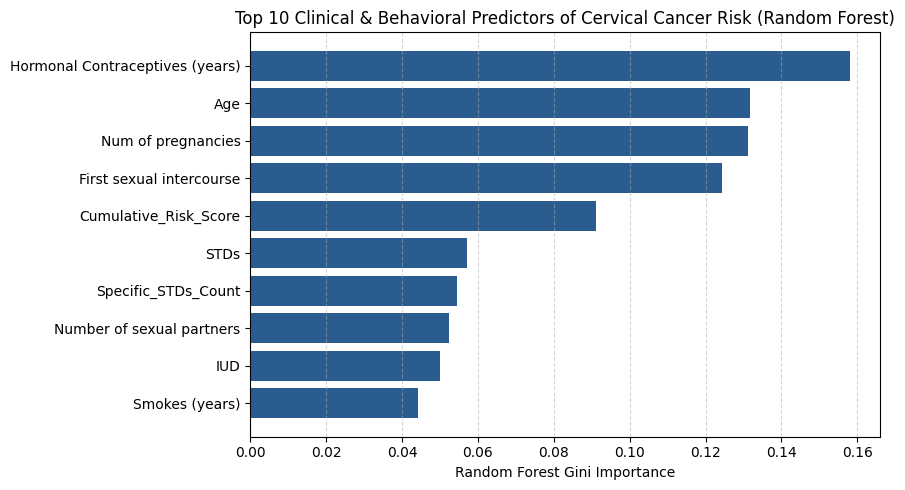

In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Extract Random Forest feature importances and flatten Logistic Regression coefficients (.ravel())
rf_best = best_models["Random Forest"]
lr_best = best_models["Logistic Regression"]

coefs_1d = lr_best.coef_.ravel()

analysis_df = pd.DataFrame({
    "Feature": X_train_final.columns,
    "RF_Importance": rf_best.feature_importances_.round(4),
    "LR_Coefficient": coefs_1d.round(4),
    "LR_Odds_Ratio": np.exp(coefs_1d).round(4)
}).sort_values(by="RF_Importance", ascending=False)

print("Objective 2: Joint Feature Importance & Logistic Regression Odds Ratios:")
display(analysis_df)

# 2. Plot Top 10 Features from Random Forest for your report
top_10 = analysis_df.head(10).sort_values(by="RF_Importance", ascending=True)

plt.figure(figsize=(9, 5))
plt.barh(top_10["Feature"], top_10["RF_Importance"], color="#2b5c8f")
plt.xlabel("Random Forest Gini Importance")
plt.title("Top 10 Clinical & Behavioral Predictors of Cervical Cancer Risk (Random Forest)")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


In [51]:
import pandas as pd
import numpy as np

# 1. Generate risk probabilities on the unseen Test Set using your best Random Forest model
rf_best = best_models["Random Forest"]
test_probs = rf_best.predict_proba(X_test_final)[:, 1]

# 2. Define 3 interpretable triage tiers around your tuned threshold (0.45)
# Low Risk (< 0.30): Routine screening schedule
# Moderate Risk (0.30 - 0.44): Priority counseling & follow-up appointment
# High Risk (>= 0.45): Immediate VIA / HPV / Pap screening slot
def assign_triage_tier(prob):
    if prob >= 0.45:
        return "Tier 1: High Priority (Immediate Screening)"
    elif prob >= 0.30:
        return "Tier 2: Moderate Priority (Scheduled Follow-Up)"
    else:
        return "Tier 3: Low Priority (Routine Care)"

triage_eval = pd.DataFrame({
    "Predicted_Risk_Prob": test_probs,
    "Actual_Biopsy": y_test.values
})
triage_eval["Triage_Tier"] = triage_eval["Predicted_Risk_Prob"].apply(assign_triage_tier)

# 3. Summarize how well the triage framework concentrates positive cases in Ugandan clinics
triage_summary = triage_eval.groupby("Triage_Tier").agg(
    Patients_Count=("Actual_Biopsy", "count"),
    Share_of_Clinic_Load_Pct=("Actual_Biopsy", lambda x: round(len(x) / len(triage_eval) * 100, 1)),
    Positive_Biopsies_Caught=("Actual_Biopsy", "sum"),
    Positive_Rate_In_Tier_Pct=("Actual_Biopsy", lambda x: round(x.mean() * 100, 2))
).reset_index()

print("Objective 3: Clinical Screening Prioritization Summary (Unseen Test Cohort, n=172):")
display(triage_summary)


Objective 3: Clinical Screening Prioritization Summary (Unseen Test Cohort, n=172):


,Triage_Tier,Patients_Count,Share_of_Clinic_Load_Pct,Positive_Biopsies_Caught,Positive_Rate_In_Tier_Pct
0,Tier 1: High Priority (Immediate Screening),48,27.9,6,12.50
1,Tier 2: Moderate Priority (Scheduled Follow-Up),123,71.5,5,4.07
2,Tier 3: Low Priority (Routine Care),1,0.6,0,0.00


=== Decision Tree (Threshold = 0.5) ===
              precision    recall  f1-score   support

Negative (0)     0.9593    0.7329    0.8310       161
Positive (1)     0.1224    0.5455    0.2000        11

    accuracy                         0.7209       172
   macro avg     0.5409    0.6392    0.5155       172
weighted avg     0.9058    0.7209    0.7906       172

=== Random Forest (Threshold = 0.45) ===
              precision    recall  f1-score   support

Negative (0)     0.9597    0.7391    0.8351       161
Positive (1)     0.1250    0.5455    0.2034        11

    accuracy                         0.7267       172
   macro avg     0.5423    0.6423    0.5192       172
weighted avg     0.9063    0.7267    0.7947       172

=== Logistic Regression (Threshold = 0.5) ===
              precision    recall  f1-score   support

Negative (0)     0.9385    0.7578    0.8385       161
Positive (1)     0.0714    0.2727    0.1132        11

    accuracy                         0.7267       172
 

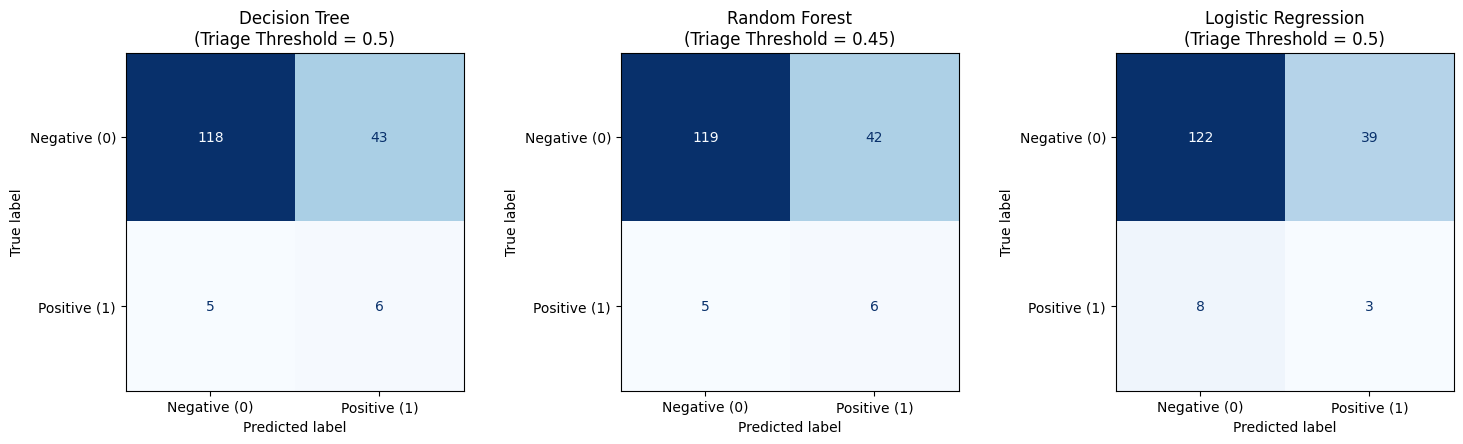

In [52]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# Use the exact CV-selected triage thresholds from your tuned table
triage_thresholds = {
    "Decision Tree": 0.50,
    "Random Forest": 0.45,
    "Logistic Regression": 0.50
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, (name, thresh) in zip(axes, triage_thresholds.items()):
    model = best_models[name]
    probs = model.predict_proba(X_test_final)[:, 1]
    preds = (probs >= thresh).astype(int)
    
    # Plot confusion matrix
    cm = confusion_matrix(y_test, preds)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Negative (0)", "Positive (1)"])
    disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{name}\n(Triage Threshold = {thresh})")
    
    # Print detailed classification report below
    print(f"=== {name} (Threshold = {thresh}) ===")
    print(classification_report(y_test, preds, target_names=["Negative (0)", "Positive (1)"], digits=4))

plt.tight_layout()
plt.show()


=== Decision Tree (Threshold = 0.5) ===
              precision    recall  f1-score   support

Negative (0)     0.9593    0.7329    0.8310       161
Positive (1)     0.1224    0.5455    0.2000        11

    accuracy                         0.7209       172
   macro avg     0.5409    0.6392    0.5155       172
weighted avg     0.9058    0.7209    0.7906       172

=== Random Forest (Threshold = 0.45) ===
              precision    recall  f1-score   support

Negative (0)     0.9597    0.7391    0.8351       161
Positive (1)     0.1250    0.5455    0.2034        11

    accuracy                         0.7267       172
   macro avg     0.5423    0.6423    0.5192       172
weighted avg     0.9063    0.7267    0.7947       172

=== Logistic Regression (Threshold = 0.5) ===
              precision    recall  f1-score   support

Negative (0)     0.9385    0.7578    0.8385       161
Positive (1)     0.0714    0.2727    0.1132        11

    accuracy                         0.7267       172
 

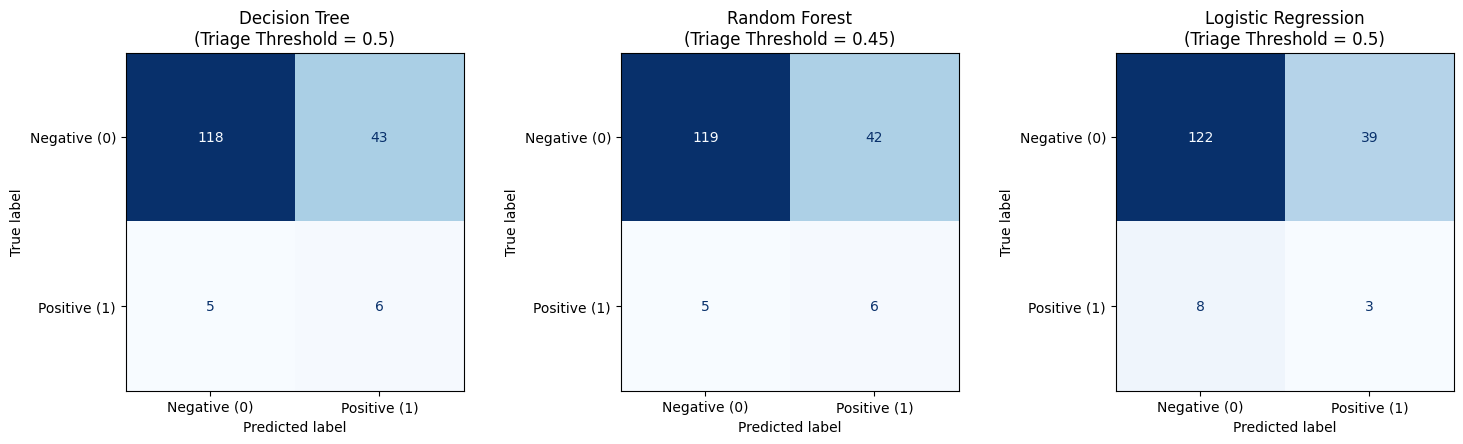

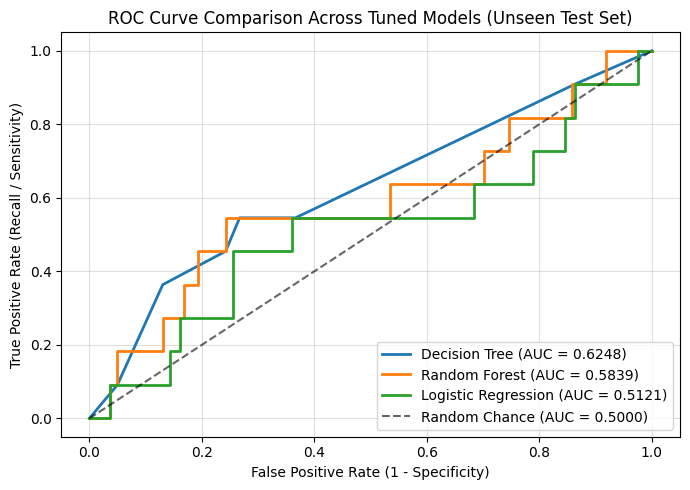

In [53]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, 
    roc_curve, roc_auc_score, classification_report
)

# Exact CV-selected triage thresholds from your tuned table
triage_thresholds = {
    "Decision Tree": 0.50,
    "Random Forest": 0.45,
    "Logistic Regression": 0.50
}

# --- PART 1: Side-by-Side Confusion Matrices ---
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, (name, thresh) in zip(axes, triage_thresholds.items()):
    model = best_models[name]
    probs = model.predict_proba(X_test_final)[:, 1]
    preds = (probs >= thresh).astype(int)
    
    cm = confusion_matrix(y_test, preds)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Negative (0)", "Positive (1)"])
    disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{name}\n(Triage Threshold = {thresh})")
    
    print(f"=== {name} (Threshold = {thresh}) ===")
    print(classification_report(y_test, preds, target_names=["Negative (0)", "Positive (1)"], digits=4))

plt.tight_layout()
plt.show()

# --- PART 2: Combined ROC Curve Comparison (Objective 1) ---
plt.figure(figsize=(7, 5))
for name in triage_thresholds.keys():
    probs = best_models[name].predict_proba(X_test_final)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc = roc_auc_score(y_test, probs)
    plt.plot(fpr, tpr, linewidth=2, label=f"{name} (AUC = {auc:.4f})")

plt.plot([0, 1], [0, 1], "k--", alpha=0.6, label="Random Chance (AUC = 0.5000)")
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Recall / Sensitivity)")
plt.title("ROC Curve Comparison Across Tuned Models (Unseen Test Set)")
plt.legend(loc="lower right")
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()
